# Project 2 – Milestone 2: Baseline Conditional Generation

This notebook uses pretrained Stable Diffusion v1.5 with its built-in CLIP text encoder to generate images from our 16 COCO 2017 captions.

We use the same prompts and random seeds from Milestone 1 to establish a reproducible baseline for the guidance-scale and sampling experiments.

Each image is generated using 25 inference steps and the default guidance scale of 7.5.

In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [2]:
!pip install -q diffusers transformers accelerate safetensors
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [3]:
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

In [4]:
print("Tokenizer:", type(pipe.tokenizer).__name__)
print("Text encoder:", type(pipe.text_encoder).__name__)
print("Denoising model:", type(pipe.unet).__name__)
print("Image decoder:", type(pipe.vae).__name__)

print("Maximum tokens:", pipe.tokenizer.model_max_length)
print("Text hidden size:", pipe.text_encoder.config.hidden_size)
print("U-Net conditioning size:", pipe.unet.config.cross_attention_dim)

Tokenizer: CLIPTokenizer
Text encoder: CLIPTextModel
Denoising model: UNet2DConditionModel
Image decoder: AutoencoderKL
Maximum tokens: 77
Text hidden size: 768
U-Net conditioning size: 768


In [5]:
# Temporary prompt to verify the integration.
prompt = "A dog running on the beach."

# Convert text into token IDs.
text_inputs = pipe.tokenizer(
    prompt,
    padding="max_length",
    max_length=pipe.tokenizer.model_max_length,
    truncation=True,
    return_tensors="pt",
)

input_ids = text_inputs.input_ids.to(pipe.device)

# Convert token IDs into contextual CLIP embeddings.
with torch.no_grad():
    prompt_embeds = pipe.text_encoder(input_ids)[0]

print("Prompt:", prompt)
print("Token IDs shape:", tuple(input_ids.shape))
print("Embeddings shape:", tuple(prompt_embeds.shape))
print("Device:", prompt_embeds.device)

Prompt: A dog running on the beach.
Token IDs shape: (1, 77)
Embeddings shape: (1, 77, 768)
Device: cuda:0


  0%|          | 0/25 [00:00<?, ?it/s]

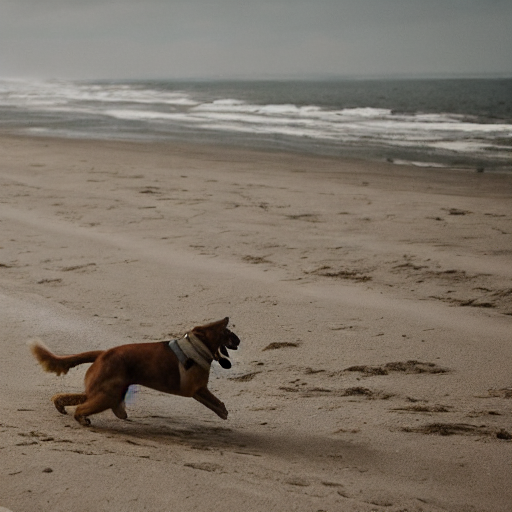

In [6]:
# Encode an empty prompt for classifier-free guidance.
negative_inputs = pipe.tokenizer(
    "",
    padding="max_length",
    max_length=pipe.tokenizer.model_max_length,
    truncation=True,
    return_tensors="pt",
)

with torch.no_grad():
    negative_prompt_embeds = pipe.text_encoder(
        negative_inputs.input_ids.to(pipe.device)
    )[0]

# Generate an image using explicitly supplied embeddings.
seed = 42

image = pipe(
    prompt_embeds=prompt_embeds,
    negative_prompt_embeds=negative_prompt_embeds,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=torch.Generator(device="cuda").manual_seed(seed),
).images[0]

display(image)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

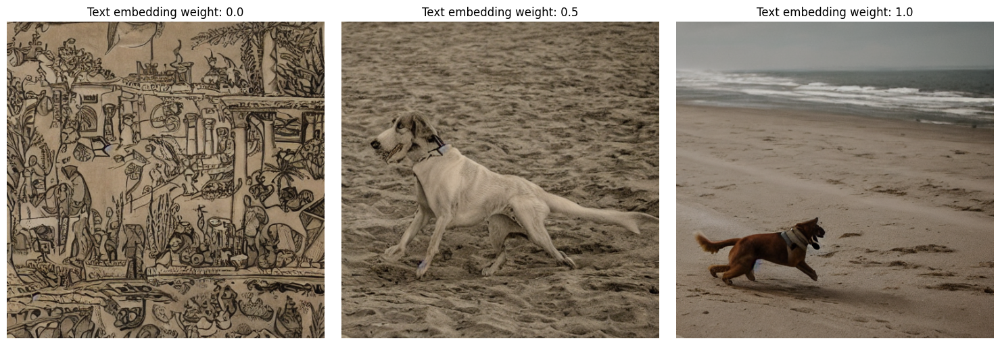

In [7]:
import matplotlib.pyplot as plt

# Preserve the image already generated with full text conditioning.
conditioning_images = {1.0: image}
conditioning_weights = [0.0, 0.5, 1.0]

for weight in conditioning_weights[:-1]:
    # Modify the conditioning path by interpolating text embeddings.
    mixed_embeds = (
        negative_prompt_embeds
        + weight * (prompt_embeds - negative_prompt_embeds)
    )

    conditioning_images[weight] = pipe(
        prompt_embeds=mixed_embeds,
        negative_prompt_embeds=negative_prompt_embeds,
        num_inference_steps=25,
        guidance_scale=7.5,
        generator=torch.Generator(device="cuda").manual_seed(seed),
    ).images[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, weight in zip(axes, conditioning_weights):
    ax.imshow(conditioning_images[weight])
    ax.set_title(f"Text embedding weight: {weight}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path
import json

output_dir = Path("integration_outputs")
output_dir.mkdir(exist_ok=True)

for weight, generated_image in conditioning_images.items():
    generated_image.save(output_dir / f"conditioning_{weight:.1f}.png")

fig.savefig(
    output_dir / "conditioning_comparison.png",
    dpi=150,
    bbox_inches="tight",
)

metadata = {
    "model_id": model_id,
    "prompt": prompt,
    "negative_prompt": "",
    "seed": seed,
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
    "scheduler": type(pipe.scheduler).__name__,
    "embedding_weights": conditioning_weights,
    "embedding_shape": list(prompt_embeds.shape),
    "modification": "Interpolation between empty and full prompt embeddings",
}

(output_dir / "parameters.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Saved files:", [p.name for p in output_dir.iterdir()])

Saved files: ['conditioning_0.5.png', 'parameters.json', 'conditioning_1.0.png', 'conditioning_comparison.png', 'conditioning_0.0.png']


In [9]:
@torch.no_grad()
def generate_with_conditioning(
    prompt,
    seed=42,
    text_weight=1.0,
    steps=25,
    guidance_scale=7.5,
):
    if not 0.0 <= text_weight <= 1.0:
        raise ValueError("text_weight must be between 0 and 1.")

    # Encode the empty prompt and the requested prompt together.
    tokens = pipe.tokenizer(
        ["", prompt],
        padding="max_length",
        max_length=pipe.tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    )

    encoder_kwargs = {}
    if getattr(pipe.text_encoder.config, "use_attention_mask", False):
        encoder_kwargs["attention_mask"] = tokens.attention_mask.to(pipe.device)

    embeddings = pipe.text_encoder(
        tokens.input_ids.to(pipe.device),
        **encoder_kwargs,
    )[0]

    empty_embeddings = embeddings[0:1]
    text_embeddings = embeddings[1:2]

    # Custom conditioning transformation.
    conditioned_embeddings = (
        empty_embeddings
        + text_weight * (text_embeddings - empty_embeddings)
    )

    return pipe(
        prompt_embeds=conditioned_embeddings,
        negative_prompt_embeds=empty_embeddings,
        num_inference_steps=steps,
        guidance_scale=guidance_scale,
        generator=torch.Generator(device="cuda").manual_seed(seed),
    ).images[0]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Mean absolute pixel difference (0–255): 3.5974


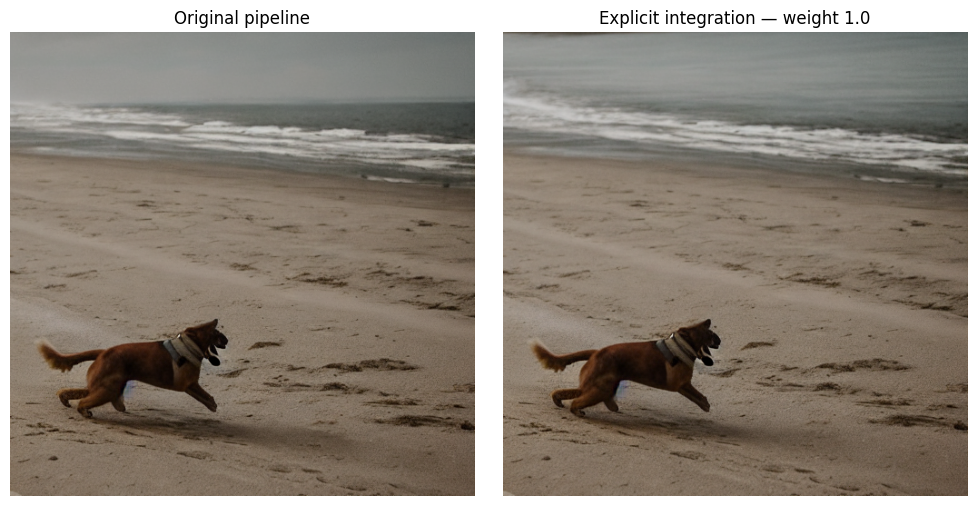

In [10]:
import numpy as np
import matplotlib.pyplot as plt

test_prompt = "A dog running on the beach."
test_seed = 42

reference_image = pipe(
    prompt=test_prompt,
    negative_prompt="",
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=torch.Generator(device="cuda").manual_seed(test_seed),
).images[0]

integrated_image = generate_with_conditioning(
    prompt=test_prompt,
    seed=test_seed,
    text_weight=1.0,
)

reference_pixels = np.asarray(reference_image).astype(np.float32)
integrated_pixels = np.asarray(integrated_image).astype(np.float32)

mae = np.abs(reference_pixels - integrated_pixels).mean()
print(f"Mean absolute pixel difference (0–255): {mae:.4f}")

fig_check, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, result, title in zip(
    axes,
    [reference_image, integrated_image],
    ["Original pipeline", "Explicit integration — weight 1.0"],
):
    ax.imshow(result)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
@torch.no_grad()
def encode_text_explicitly(text):
    tokens = pipe.tokenizer(
        [text],
        padding="max_length",
        max_length=pipe.tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    )

    attention_mask = None
    if getattr(pipe.text_encoder.config, "use_attention_mask", False):
        attention_mask = tokens.attention_mask.to(pipe.device)

    return pipe.text_encoder(
        tokens.input_ids.to(pipe.device),
        attention_mask=attention_mask,
    )[0].to(dtype=pipe.text_encoder.dtype)


@torch.no_grad()
def generate_with_conditioning(
    prompt,
    seed=42,
    text_weight=1.0,
    steps=25,
    guidance_scale=7.5,
):
    if not 0.0 <= text_weight <= 1.0:
        raise ValueError("text_weight must be between 0 and 1.")

    text_embeddings = encode_text_explicitly(prompt)
    empty_embeddings = encode_text_explicitly("")

    if text_weight == 1.0:
        conditioned_embeddings = text_embeddings
    elif text_weight == 0.0:
        conditioned_embeddings = empty_embeddings
    else:
        conditioned_embeddings = (
            empty_embeddings.float()
            + text_weight
            * (text_embeddings.float() - empty_embeddings.float())
        ).to(text_embeddings.dtype)

    return pipe(
        prompt_embeds=conditioned_embeddings,
        negative_prompt_embeds=empty_embeddings,
        num_inference_steps=steps,
        guidance_scale=guidance_scale,
        height=512,
        width=512,
        generator=torch.Generator(device="cuda").manual_seed(int(seed)),
    ).images[0]

In [12]:
from pathlib import Path
from datetime import datetime, timezone
import json
import time
import shutil
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import diffusers
import transformers

OUT = Path("/content/integration_point1")
(OUT / "images").mkdir(parents=True, exist_ok=True)

for component in [pipe.text_encoder, pipe.unet, pipe.vae]:
    component.eval()
    component.requires_grad_(False)

pipe.set_progress_bar_config(disable=True)

# Fixed diagnostic prompts from the project's validation split.
validation = pd.DataFrame([
    ("v01", "coco2017val_000000565563",
     "Many cars are parked along the sidewalk of a narrow street.", 1001),
    ("v02", "coco2017val_000000199055",
     "A person on skateboard skating on the pavement.", 1002),
    ("v03", "coco2017val_000000352491",
     "A train sitting idle in an empty train station", 1003),
    ("v04", "coco2017val_000000341973",
     "Two girls pose for a photo holding doughnuts.", 1004),
], columns=["prompt_id", "pair_id", "prompt", "seed"])
validation["split"] = "validation"

# Original baseline prompts and seeds: compatibility checks only.
evaluation = pd.DataFrame([
    ("p01", "A kitchen with a center white island topped with a bowl of greens.", 42),
    ("p02", "Three pastry desserts and two glasses of wine are on a table.", 43),
    ("p03", "A waterway under a bridge with people sitting down and a woman taking a photo.", 44),
    ("p04", "A black and white cat sitting on top of a chair.", 45),
    ("p05", "A woman holding a small cake with lit candles.", 46),
    ("p06", "A flock of animals stand on the road near mountains.", 47),
    ("p07", "Baseball memorabilia is displayed in glass stacked casings.", 48),
    ("p08", "The two cats are laying beside of the computer on the keyboard.", 49),
    ("p09", "A newly married couple walking down a street.", 50),
    ("p10", "The skateboarder wears headphones while jumping to grab his board.", 51),
    ("p11", "A clean industrial kitchen with no one in it", 52),
    ("p12", "A woman in a living room with a dog.", 53),
    ("p13", "a male tennis player in white shorts is playing tennis", 54),
    ("p14", "A green netted bed in a light filled bedroom.", 55),
    ("p15", "Three fire hydrants in front of a huge building.", 56),
    ("p16", "A white toilet sitting next to a trash can in a restroom.", 57),
], columns=["prompt_id", "prompt", "seed"])
evaluation["split"] = "evaluation"

test_cases = pd.concat([validation, evaluation], ignore_index=True)
test_cases.to_csv(OUT / "test_prompts.csv", index=False)

environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model_id": model_id,
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "diffusers": diffusers.__version__,
    "transformers": transformers.__version__,
    "dtype": str(pipe.text_encoder.dtype),
    "scheduler": type(pipe.scheduler).__name__,
    "scheduler_config": dict(pipe.scheduler.config),
    "steps": 25,
    "guidance_scale": 7.5,
    "resolution": [512, 512],
    "training_performed": False,
    "baseline_prompts_git_blob": "736ecbd48e2b65af9130ae25f2fe491d8d7e9dba",
    "manifest_git_blob": "708184ef2a519567c85776f0baa9ccfa06e4aa15",
}

(OUT / "environment.json").write_text(
    json.dumps(environment, indent=2, default=str), encoding="utf-8"
)

# Preserve the earlier demonstration.
if Path("integration_outputs").exists():
    shutil.copytree(
        "integration_outputs", OUT / "initial_demo", dirs_exist_ok=True
    )

print("Ready: 4 validation prompts and 16 baseline prompts.")
print("Planned image generations: 48")

Ready: 4 validation prompts and 16 baseline prompts.
Planned image generations: 48


In [13]:
records = []
comparisons = []
architecture_trace = {}
active_run = {"mode": ""}


def capture_unet_inputs(module, args, kwargs):
    if architecture_trace or active_run["mode"] != "weight_1.0":
        return

    architecture_trace.update({
        "mode": active_run["mode"],
        "latent_input_shape": list(args[0].shape),
        "conditioning_shape": list(kwargs["encoder_hidden_states"].shape),
        "conditioning_entry": "U-Net encoder_hidden_states",
    })


hook = pipe.unet.register_forward_pre_hook(
    capture_unet_inputs, with_kwargs=True
)

try:
    for row in test_cases.itertuples(index=False):
        modes = [("original", None), ("weight_1.0", 1.0)]

        if row.split == "validation":
            modes += [("weight_0.0", 0.0), ("weight_0.5", 0.5)]

        images_for_prompt = {}

        for mode, weight in modes:
            active_run["mode"] = mode

            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
            started = time.perf_counter()

            if mode == "original":
                generated = pipe(
                    prompt=row.prompt,
                    negative_prompt="",
                    num_inference_steps=25,
                    guidance_scale=7.5,
                    height=512,
                    width=512,
                    generator=torch.Generator(device="cuda").manual_seed(
                        int(row.seed)
                    ),
                ).images[0]
            else:
                generated = generate_with_conditioning(
                    row.prompt, seed=int(row.seed), text_weight=weight
                )

            torch.cuda.synchronize()
            elapsed = time.perf_counter() - started
            peak_mib = torch.cuda.max_memory_allocated() / (1024 ** 2)

            filename = f"{row.prompt_id}_{mode}.png"
            generated.save(OUT / "images" / filename)
            images_for_prompt[mode] = generated

            records.append({
                "prompt_id": row.prompt_id,
                "split": row.split,
                "prompt": row.prompt,
                "seed": int(row.seed),
                "mode": mode,
                "text_weight": weight,
                "steps": 25,
                "guidance_scale": 7.5,
                "runtime_seconds": elapsed,
                "peak_allocated_mib": peak_mib,
                "image_all_black": not bool(np.asarray(generated).any()),
                "image_file": f"images/{filename}",
            })

            pd.DataFrame(records).to_csv(OUT / "run_logs.csv", index=False)
            print(f"{len(records):02d}/48 | {row.prompt_id} | "
                  f"{mode} | {elapsed:.1f}s", flush=True)

        original = np.asarray(
            images_for_prompt["original"]
        ).astype(np.float32)
        explicit = np.asarray(
            images_for_prompt["weight_1.0"]
        ).astype(np.float32)

        comparisons.append({
            "prompt_id": row.prompt_id,
            "split": row.split,
            "pixel_mae": float(np.abs(original - explicit).mean()),
            "identical_pixels": bool(np.array_equal(original, explicit)),
        })

        pd.DataFrame(comparisons).to_csv(
            OUT / "compatibility_checks.csv", index=False
        )

finally:
    hook.remove()
    (OUT / "architecture_trace.json").write_text(
        json.dumps(architecture_trace, indent=2), encoding="utf-8"
    )

print("\nFinished.")
display(pd.DataFrame(comparisons))

01/48 | v01 | original | 4.3s
02/48 | v01 | weight_1.0 | 4.3s
03/48 | v01 | weight_0.0 | 4.3s
04/48 | v01 | weight_0.5 | 4.3s
05/48 | v02 | original | 4.4s
06/48 | v02 | weight_1.0 | 4.4s
07/48 | v02 | weight_0.0 | 4.4s
08/48 | v02 | weight_0.5 | 4.4s
09/48 | v03 | original | 4.3s
10/48 | v03 | weight_1.0 | 4.3s
11/48 | v03 | weight_0.0 | 4.3s
12/48 | v03 | weight_0.5 | 4.3s
13/48 | v04 | original | 4.3s
14/48 | v04 | weight_1.0 | 4.3s
15/48 | v04 | weight_0.0 | 4.3s
16/48 | v04 | weight_0.5 | 4.3s
17/48 | p01 | original | 4.3s
18/48 | p01 | weight_1.0 | 4.3s
19/48 | p02 | original | 4.3s
20/48 | p02 | weight_1.0 | 4.3s
21/48 | p03 | original | 4.3s
22/48 | p03 | weight_1.0 | 4.3s
23/48 | p04 | original | 4.3s
24/48 | p04 | weight_1.0 | 4.3s
25/48 | p05 | original | 4.3s
26/48 | p05 | weight_1.0 | 4.3s
27/48 | p06 | original | 4.3s
28/48 | p06 | weight_1.0 | 4.3s
29/48 | p07 | original | 4.3s
30/48 | p07 | weight_1.0 | 4.3s
31/48 | p08 | original | 4.3s
32/48 | p08 | weight_1.0 | 4.3s


,prompt_id,split,pixel_mae,identical_pixels
0,v01,validation,0.0,True
1,v02,validation,0.0,True
2,v03,validation,0.0,True
3,v04,validation,0.0,True
4,p01,evaluation,0.0,True
5,p02,evaluation,0.0,True
6,p03,evaluation,0.0,True
7,p04,evaluation,0.0,True
8,p05,evaluation,0.0,True
9,p06,evaluation,0.0,True


{
  "completed_generations": 48,
  "expected_generations": 48,
  "compared_prompts": 20,
  "pixel_identical_comparisons": 20,
  "mean_pixel_mae": 0.0,
  "maximum_pixel_mae": 0.0,
  "total_measured_inference_seconds": 206.13425968299907,
  "maximum_allocated_gpu_mib": 3257.86865234375,
  "all_black_images": 0,
  "training_performed": false,
  "limitation": "One fixed seed per prompt; no quantitative alignment metric."
}

U-Net input trace: {'mode': 'weight_1.0', 'latent_input_shape': [2, 4, 64, 64], 'conditioning_shape': [2, 77, 768], 'conditioning_entry': 'U-Net encoder_hidden_states'}


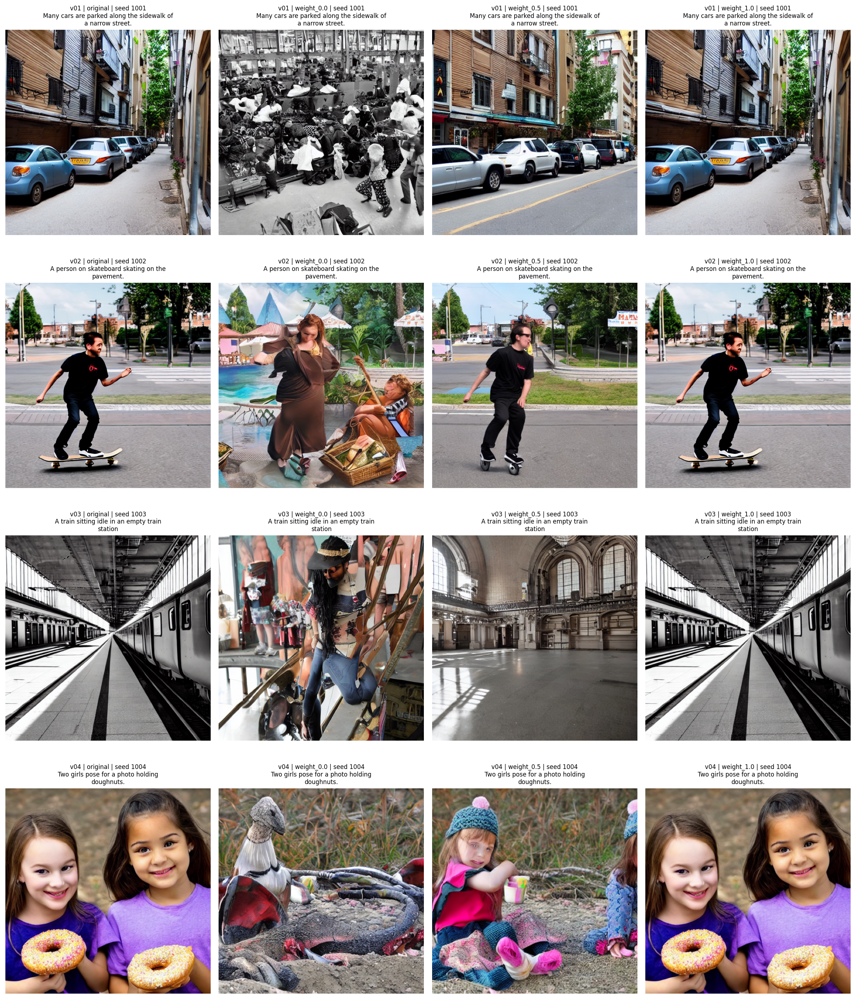

In [14]:
def save_gallery(rows, modes, filename):
    fig, axes = plt.subplots(
        len(rows), len(modes),
        figsize=(4 * len(modes), 4.8 * len(rows)),
        squeeze=False,
    )

    for i, row in enumerate(rows.itertuples(index=False)):
        for j, mode in enumerate(modes):
            path = OUT / "images" / f"{row.prompt_id}_{mode}.png"
            with Image.open(path) as img:
                axes[i, j].imshow(img)

            caption = textwrap.fill(row.prompt, width=42)
            axes[i, j].set_title(
                f"{row.prompt_id} | {mode} | seed {row.seed}\n{caption}",
                fontsize=8,
            )
            axes[i, j].axis("off")

    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=150, bbox_inches="tight")
    plt.close(fig)


save_gallery(
    validation,
    ["original", "weight_0.0", "weight_0.5", "weight_1.0"],
    "validation_gallery.png",
)

for start in range(0, len(evaluation), 4):
    save_gallery(
        evaluation.iloc[start:start + 4],
        ["original", "weight_1.0"],
        f"baseline_comparison_page_{start // 4 + 1}.png",
    )

logs = pd.DataFrame(records)
checks = pd.DataFrame(comparisons)

summary = {
    "completed_generations": len(logs),
    "expected_generations": 48,
    "compared_prompts": len(checks),
    "pixel_identical_comparisons": int(checks["identical_pixels"].sum()),
    "mean_pixel_mae": float(checks["pixel_mae"].mean()),
    "maximum_pixel_mae": float(checks["pixel_mae"].max()),
    "total_measured_inference_seconds": float(logs["runtime_seconds"].sum()),
    "maximum_allocated_gpu_mib": float(logs["peak_allocated_mib"].max()),
    "all_black_images": int(logs["image_all_black"].sum()),
    "training_performed": False,
    "limitation": "One fixed seed per prompt; no quantitative alignment metric.",
}

(OUT / "summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

observations = validation[["prompt_id", "pair_id", "prompt", "seed"]].copy()
for column in ["weight_0_observation", "weight_05_observation",
               "weight_1_observation"]:
    observations[column] = ""
observations.to_csv(OUT / "observations_to_complete.csv", index=False)

(OUT / "method_notes.md").write_text(
    """# Text-encoder integration

The pretrained Stable Diffusion v1.5 weights remain frozen.
No training or fine-tuning was performed.

Architecture:
Text -> CLIP tokenizer -> CLIP token-level hidden states (1, 77, 768)
-> embedding interpolation -> U-Net cross-attention
-> scheduler denoising steps -> VAE decoding -> image.

Custom conditioning:
h(alpha) = h(empty) + alpha * (h(text) - h(empty)).
The empty-prompt embeddings remain the classifier-free guidance reference.
Alpha 0 and 1 use the original endpoint embeddings directly.

Four validation captions were used for the fixed alpha settings 0, 0.5 and 1.
The 16 original baseline prompts were used only to check compatibility
between the standard pipeline and the explicit integration at alpha 1.
No setting was selected using the evaluation outputs.

All runs use 512x512 resolution, 25 steps, guidance scale 7.5,
and the same seed within each comparison.
The scheduler and software versions are recorded in environment.json.

Pixel MAE measures output compatibility, not image quality.
Visual alignment observations must be completed after inspecting the galleries.
Runtime measurements include text encoding, generation and pipeline processing,
but exclude initial model loading and writing image files.
GPU memory is peak allocated process memory, including resident model weights.

Sources:
https://github.com/Yosephines/IE7615-Group1-Project2
https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/text2img
""",
    encoding="utf-8",
)

print(json.dumps(summary, indent=2))
print("\nU-Net input trace:", architecture_trace)
display(Image.open(OUT / "validation_gallery.png"))

In [15]:
from google.colab import files

archive = shutil.make_archive(
    "/content/integration_point1_results",
    "zip",
    root_dir=str(OUT),
)

print(f"Archive size: {Path(archive).stat().st_size / 1024**2:.1f} MiB")
files.download(archive)

Archive size: 39.7 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>